# 071 — ensemble 058 svm

Ensemble 058 com SVM calibrado; pesos 0/0,1/0,25/0,5/1 do SVM, incluindo os modelos individuais.

**Estado: executado pelo runner; outputs guardados.**

Seleção dentro do treino de desenvolvimento (8.769 linhas), com os mesmos três folds. Validação fixa: 2.193 linhas, já observada anteriormente. Pré-processamento ajustado dentro de cada treino. Sem submissão automática.

071 resultado completo reutilizado após verificar o contexto.
Estado: procedimento concluído; resultados guardados com contexto verificado.
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração original (s): 2.2121532919991296
Notas: Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.
Selecionado: controlo_058
Configuração: {'family': 'legacy_058', 'xgb': {'label': 'combinado', 'kind': 'xgb', 'params': {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}, 'weighting': 'none'}, 'weight': 0.6}
Diferenças emparelhadas: {'differences': [0.0, 0.0, 0.0], 'mean': 0.0, 'std': 0.0}
Escalões: controlo
Diagnósticos de ajuste: {'note': 'MLP histórico de 85 

,configuração,Macro F1 CV,DP,folds
0,controlo_058,0.459383,0.008737,"[0.4688505872367493, 0.45163118425848314, 0.45..."
1,peso_extra_0.1,0.457761,0.010241,"[0.46810901044026193, 0.44763059295721125, 0.4..."
2,peso_extra_0.25,0.454185,0.007113,"[0.4623714601208088, 0.449509894422895, 0.4506..."
3,peso_extra_0.5,0.450072,0.008074,"[0.458134184938076, 0.4500962918288641, 0.4419..."
4,peso_extra_1,0.419975,0.006389,"[0.4270575113191673, 0.4146450402258998, 0.418..."


,modelo,parcela,Macro F1,accuracy
0,controlo,train,0.930239,0.920629
1,controlo,validation,0.462412,0.465572
2,selecionado,train,0.930239,0.920629
3,selecionado,validation,0.462412,0.465572


,classe,precision,recall,F1,support
0,0,0.840909,0.902439,0.870588,41
1,1,0.478261,0.323529,0.385965,34
2,2,0.552941,0.587500,0.569697,80
3,3,0.333333,0.320000,0.326531,75
4,4,0.328767,0.266667,0.294479,90
5,5,0.320261,0.379845,0.347518,129
6,6,0.371622,0.319767,0.343750,172
7,7,0.372093,0.369942,0.371014,173
8,8,0.595122,0.674033,0.632124,181
9,9,0.647059,0.650246,0.648649,203


,classe,precision,recall,F1,support
0,0,0.840909,0.902439,0.870588,41
1,1,0.478261,0.323529,0.385965,34
2,2,0.552941,0.587500,0.569697,80
3,3,0.333333,0.320000,0.326531,75
4,4,0.328767,0.266667,0.294479,90
5,5,0.320261,0.379845,0.347518,129
6,6,0.371622,0.319767,0.343750,172
7,7,0.372093,0.369942,0.371014,173
8,8,0.595122,0.674033,0.632124,181
9,9,0.647059,0.650246,0.648649,203


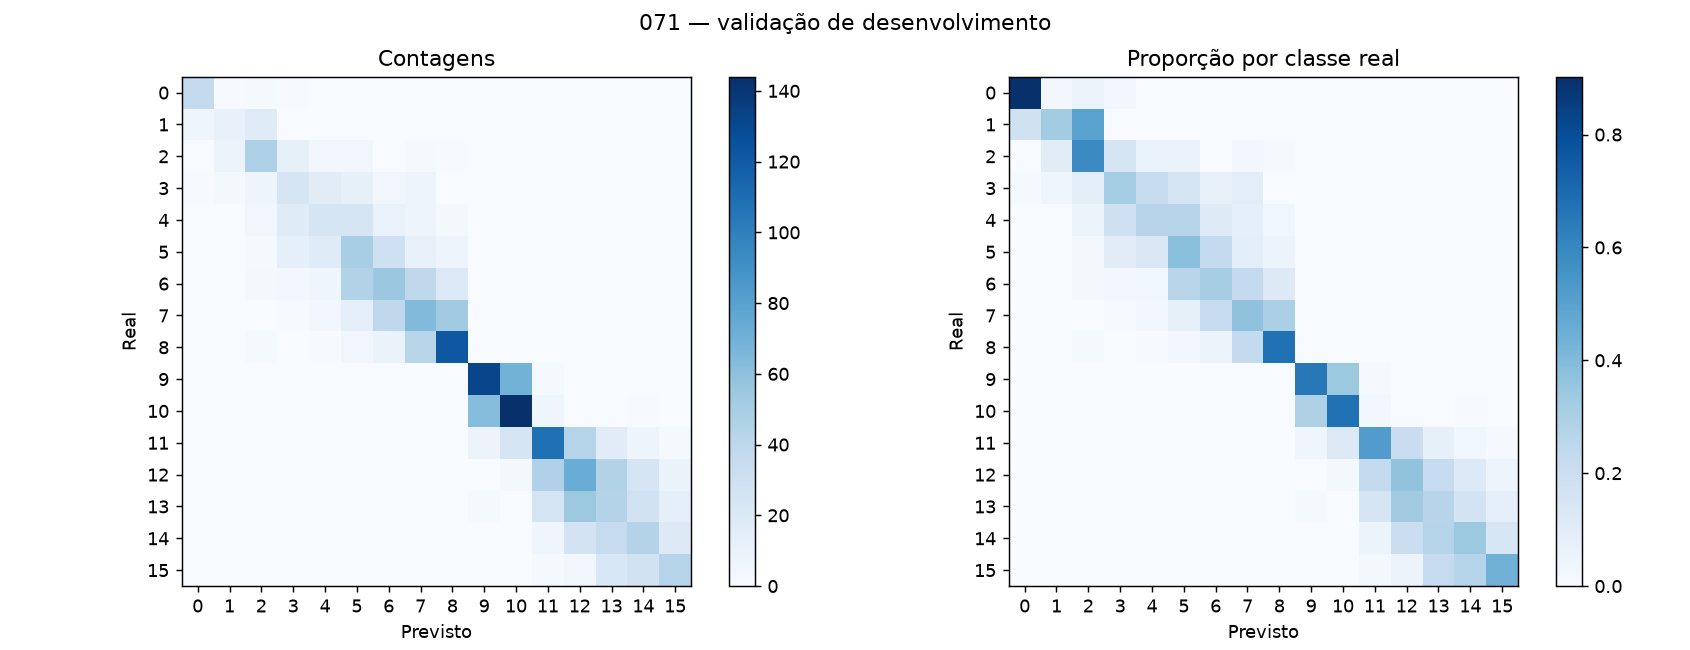

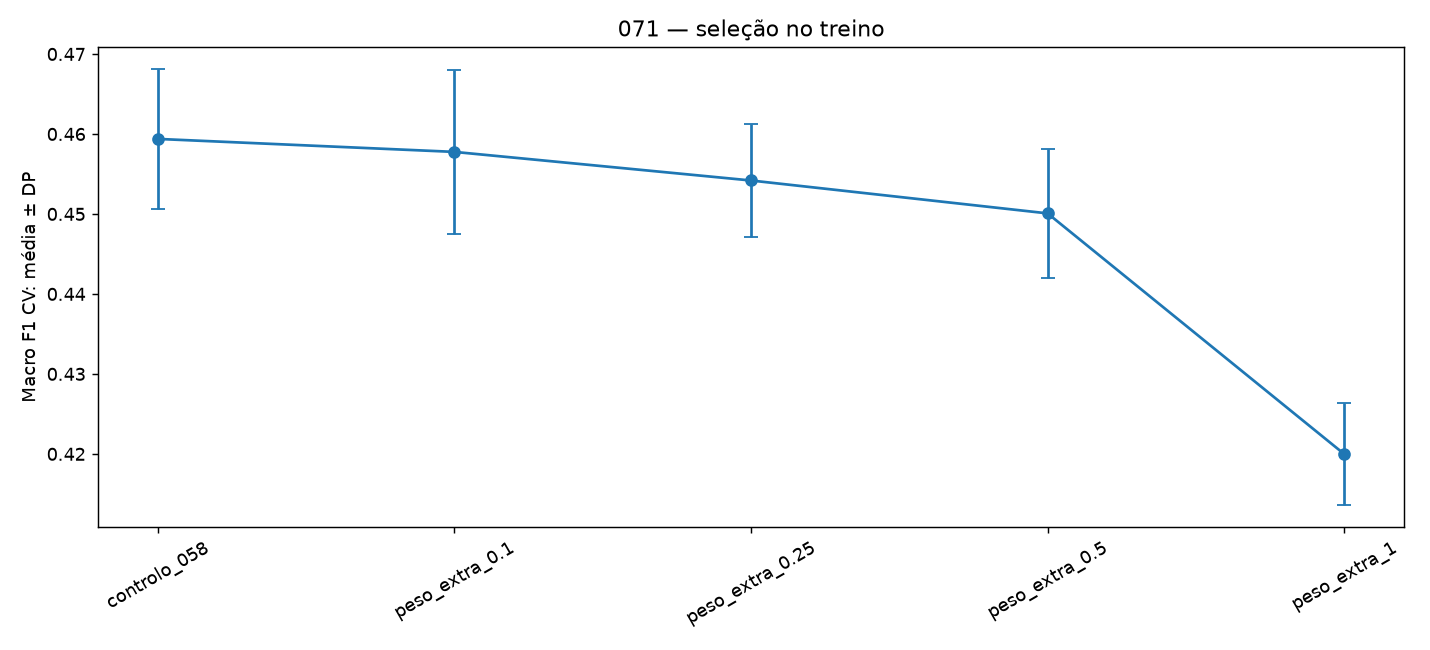

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p/'src/experiments_059_075.py').is_file())
sys.path.insert(0, str(root))
from src.experiments_059_075 import run_experiment
result = run_experiment('071')
print('Estado: procedimento concluído; resultados guardados com contexto verificado.')
print('Versões:', result['context']['base']['versions'])
print('Duração original (s):', result['seconds'])
print('Notas:', result.get('note', ''))
if result.get('candidates'):
    display(pd.DataFrame([{'configuração':r['label'],'Macro F1 CV':r['mean'],'DP':r['std'],'folds':r.get('folds',r.get('scores'))} for r in result['candidates']]))
if result.get('selected'):
    print('Selecionado:', result['selected']['label'])
    print('Configuração:', result['selected']['spec'])
if result.get('paired_cv'):
    print('Diferenças emparelhadas:', result['paired_cv'])
if result.get('fixed'):
    display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':groups[part]['macro_f1'],'accuracy':groups[part]['accuracy']} for name,groups in result['fixed'].items() for part in ['train','validation']]))
    for name, groups in result['fixed'].items():
        print('Escalões:', name)
        display(pd.DataFrame(groups['validation']['per_class']))
        print('Diagnósticos de ajuste:', groups.get('diagnostics'))
        print('MAE em códigos de escalão (não anos):', groups.get('mae_in_class_codes'))
        if 'log_loss' in groups: print('Log loss:',groups['log_loss'])
if result.get('metrics_oof'):
    print('Métricas OOF de desenvolvimento:', result['metrics_oof']['macro_f1'], result['metrics_oof']['accuracy'])
    display(pd.DataFrame(result['metrics_oof']['per_class']))
if 'selected_cases' in result:
    print('Perfis sinalizados:', result['flagged'], '/', result['total'])
    display(pd.DataFrame(result['selected_cases']))
    display(pd.DataFrame(result['by_class']))
if 'categorical_profiles' in result:
    table = pd.DataFrame(result['categorical_profiles'])
    display(table[table.variable.isin(['HATLEVEL','MAINSTAT','HHINCOME','HS1','HS2'])])
    display(pd.DataFrame(result['numeric_profiles']))
    display(pd.DataFrame(result['chronic_diseases']))
for file in sorted((root/'reports').glob('experiencia_071_*.png')):
    display(Image(filename=str(file)))
print('CSV Kaggle:', result.get('submission'))
print('Pontuação Kaggle:', result['kaggle_score'])


## Conclusões locais

- Selecionado internamente: `controlo_058`.
- Macro F1 desenvolvimento: **0.4624**; accuracy: **0.4656**.
- Diferença face ao controlo contemporâneo: **+0.0000**.
- Diferença média nos mesmos folds: **+0.0000**, DP **0.0000**.
- CSV: `None`. Motivo se não criado: O controlo venceu a seleção interna; sem novo CSV..

Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.

**Decisão:** preencher depois da revisão; não inferir melhoria pública de uma pequena diferença local.

## Registo manual

- Data:
- CSV submetido (se aplicável):
- Nota Kaggle:
- Conclusão:
- Melhorias a experimentar:

Esta célula e quaisquer notas pessoais não são substituídas pelo script.